# Chapitre 6 - Lissage par noyaux (2) : dimension $p$, vraisemblance locale, densités, mélanges

Ce second notebook couvre les sections 6.3 à 6.8 du livre :
1. la régression locale dans $\mathbb R^p$ et ses limites (fig. 6.8, données *galaxy*) ;
2. les modèles locaux **structurés** : noyaux structurés, modèles additifs, conditionnement
   (fig. 6.9, données *ozone*), modèles à coefficients variables (fig. 6.10-6.11) ;
3. la **vraisemblance locale** : régression logistique locale (fig. 6.12, *SAheart*) ;
4. l'**estimation de densité** par noyau et la classification qui en découle, dont le
   **Bayes naïf** (fig. 6.13-6.15) ;
5. les **fonctions de base radiales** (fig. 6.16) ;
6. les **mélanges gaussiens** et l'algorithme EM (fig. 6.17).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]
rng = np.random.RandomState(0)

## 1. Régression locale dans $\mathbb R^p$

Tout se généralise directement. Soit $b(X)$ le vecteur des monômes en $X \in \mathbb R^p$
de degré au plus $d$ ; par exemple pour $p = 2$ :
- $d = 0$ : $b(X) = 1$ ;
- $d = 1$ : $b(X) = (1, X_1, X_2)$ ;
- $d = 2$ : $b(X) = (1, X_1, X_2, X_1^2, X_2^2, X_1X_2)$.

En chaque $x_0 \in \mathbb R^p$ on résout (éq. (6.12) du livre)
$$
\min_{\beta(x_0)} \sum_{i=1}^N K_\lambda(x_0, x_i)\,\big(y_i - b(x_i)^T\beta(x_0)\big)^2,
\qquad \hat f(x_0) = b(x_0)^T\hat\beta(x_0),
$$
avec un noyau **radial** (éq. (6.13)) : $K_\lambda(x_0, x) = D(\|x - x_0\|/\lambda)$,
$\|\cdot\|$ la norme euclidienne.

> **Remarque.** La norme euclidienne dépend des unités de chaque coordonnée : on
> **standardise** en général les prédicteurs (écart-type 1) avant de lisser.

> **Intuition.** Les effets de bord sont bien pires en dimension 2 ou plus, car la
> proportion de points proches du bord est plus grande. La régression **linéaire** locale
> corrige automatiquement le biais de bord au premier ordre, quelle que soit la forme
> (même très irrégulière) du bord : c'est pourquoi on la préfère à Nadaraya-Watson.

### Proportion de points « au bord »

Pour $X$ uniforme sur $[0,1]^p$, la probabilité d'être à distance $< 0{,}05$ du bord est
$1 - \mathbb P(\text{toutes les coordonnées dans } [0{,}05;\,0{,}95]) = 1 - 0{,}9^p$
(indépendance des coordonnées). Elle tend vers 1 : c'est une manifestation du **fléau de
la dimension**.

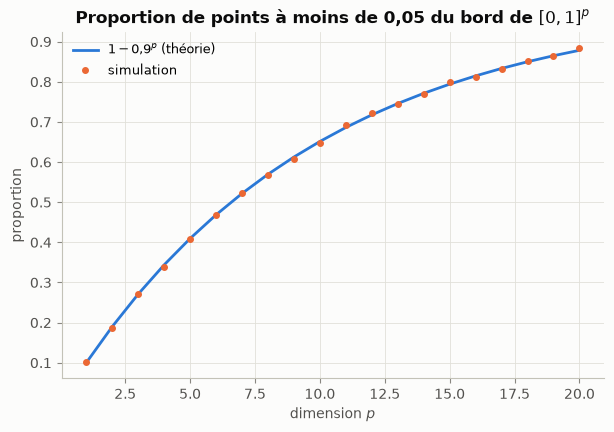

In [2]:
ps = np.arange(1, 21)
emp = [np.mean(np.any((U < 0.05) | (U > 0.95), axis=1))
       for U in (rng.uniform(size=(20000, p)) for p in ps)]
plt.figure(figsize=(7, 4.5))
plt.plot(ps, 1 - 0.9 ** ps, label="$1 - 0{,}9^p$ (théorie)")
plt.plot(ps, emp, "o", ms=4, label="simulation")
plt.title("Proportion de points à moins de 0,05 du bord de $[0,1]^p$")
plt.xlabel("dimension $p$"); plt.ylabel("proportion"); plt.legend(); plt.show()

### Figure 6.8 : les données *galaxy*

La réponse est la vitesse radiale mesurée sur la galaxie NGC 7531 ; les deux prédicteurs
sont des positions (est-ouest, sud-nord) sur la sphère céleste. Les mesures ont été faites
le long de fentes rayonnantes, d'où un plan d'expérience **en étoile** au bord très
irrégulier.

In [3]:
gal = datasets.load_galaxy()
Xg = gal[["east.west", "north.south"]].to_numpy()
yg = gal["velocity"].to_numpy()
print(gal.shape)
gal.head()

(323, 5)


,east.west,north.south,angle,radial.position,velocity
0,8.462789,-38.173172,102.5,39.099998,1769
1,7.964978,-35.927692,102.5,36.799999,1749
2,7.467167,-33.682213,102.5,34.500001,1749
3,6.969356,-31.436731,102.5,32.200000,1758
4,6.471544,-29.191250,102.5,29.899999,1750


On ajuste une régression **linéaire locale** dans $\mathbb R^2$ (tri-cube) avec une fenêtre
des plus proches voisins contenant 15 % des données, comme dans le livre. On n'affiche
l'ajustement qu'à l'intérieur de l'enveloppe convexe des données (au-delà on extrapolerait).

In [4]:
from scipy.spatial import Delaunay

kg = int(round(0.15 * len(yg)))
g1 = np.linspace(Xg[:, 0].min(), Xg[:, 0].max(), 70)
g2 = np.linspace(Xg[:, 1].min(), Xg[:, 1].max(), 70)
G1, G2 = np.meshgrid(g1, g2)
Q = np.column_stack([G1.ravel(), G2.ravel()])
inside = Delaunay(Xg).find_simplex(Q) >= 0
fit = np.full(Q.shape[0], np.nan)
fit[inside] = nk.local_regression(Q[inside], Xg, yg, k=kg, degree=1, kernel="tricube")
print("k = %d voisins ; ajustement calculé en %d points de grille" % (kg, inside.sum()))

k = 48 voisins ; ajustement calculé en 4113 points de grille


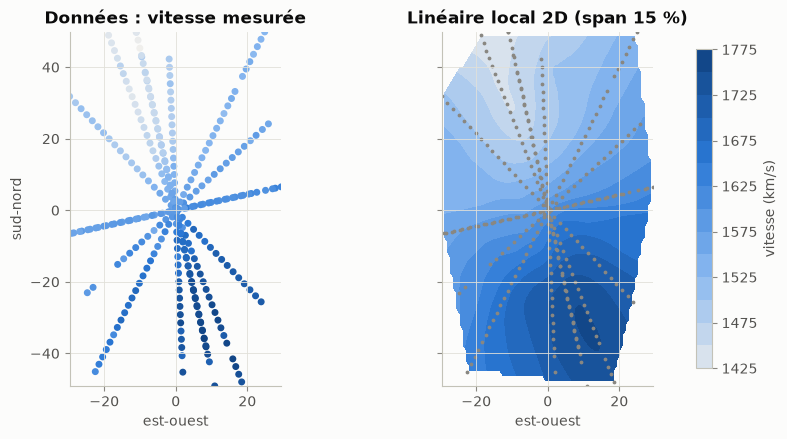

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
vmin, vmax = yg.min(), yg.max()
sc = axes[0].scatter(Xg[:, 0], Xg[:, 1], c=yg, cmap=SEQ, s=16, vmin=vmin, vmax=vmax)
axes[0].set_title("Données : vitesse mesurée")
cf = axes[1].contourf(G1, G2, fit.reshape(G1.shape), levels=15, cmap=SEQ, vmin=vmin, vmax=vmax)
axes[1].scatter(Xg[:, 0], Xg[:, 1], s=3, color=GRAY)
axes[1].set_title("Linéaire local 2D (span 15 %)")
for ax in axes:
    ax.set_xlabel("est-ouest"); ax.set_aspect("equal")
axes[0].set_ylabel("sud-nord")
fig.colorbar(cf, ax=axes, label="vitesse (km/s)", shrink=0.9)
plt.show()

La surface obtenue est lisse et interpole raisonnablement entre les branches de l'étoile,
là où les données se raréfient. On y voit la rotation de la galaxie : vitesses élevées
d'un côté, faibles de l'autre.

> **À retenir.** Au-delà de $p = 2$ ou $3$, la régression locale perd beaucoup d'intérêt :
> on ne peut pas à la fois garder des voisinages **petits** (biais faible) et **peuplés**
> (variance faible) sans une taille d'échantillon qui croît exponentiellement avec $p$.
> On impose alors de la **structure**.

## 2. Modèles locaux structurés

### Noyaux structurés (éq. (6.14))

Au lieu d'un noyau sphérique, on peut pondérer les directions par une matrice
semi-définie positive $\mathbf A$ :
$$
K_{\lambda, A}(x_0, x) = D\!\left(\frac{(x - x_0)^T\mathbf A(x - x_0)}{\lambda}\right).
$$
Avec $\mathbf A$ diagonale on augmente ou diminue l'influence de chaque prédicteur ; un
coefficient nul supprime une variable de la distance. Pour des prédicteurs très corrélés
(signaux, images), on peut construire $\mathbf A$ à partir de leur covariance
(exercice 6.4). Dans le module, `A` définit la distance $\sqrt{(x-x_0)^T\mathbf A(x-x_0)}$.

### Fonctions de régression structurées : décomposition ANOVA (éq. (6.15))

On écrit
$$
f(X_1,\dots,X_p) = \alpha + \sum_j g_j(X_j) + \sum_{k<\ell} g_{k\ell}(X_k, X_\ell) + \cdots
$$
et on supprime les termes d'ordre élevé. Le **modèle additif** ne garde que les effets
principaux $g_j$. On l'ajuste par **backfitting** (chapitre 9) : si tous les termes sauf
$g_k$ sont connus, on estime $g_k$ par régression locale **unidimensionnelle** des résidus
partiels $y - \alpha - \sum_{j\ne k} g_j(X_j)$ sur $X_k$ ; on cycle jusqu'à convergence.

### Les données *ozone*

111 jours de mesures à New York : concentration d'ozone, rayonnement solaire, température
et vitesse du vent. Comme le livre, on modélise la **racine cubique** de l'ozone.

In [6]:
oz = datasets.load_ozone()
yo = np.cbrt(oz["ozone"].to_numpy())
Xo = oz[["radiation", "temperature", "wind"]].to_numpy(float)
names = ["rayonnement", "température", "vent"]
oz.describe().round(1)

,ozone,radiation,temperature,wind
count,111.0,111.0,111.0,111.0
mean,42.1,184.8,77.8,9.9
std,33.3,91.2,9.5,3.6
min,1.0,7.0,57.0,2.3
25%,18.0,113.5,71.0,7.4
50%,31.0,207.0,79.0,9.7
75%,62.0,255.5,84.5,11.5
max,168.0,334.0,97.0,20.7


Backfitting d'un modèle additif avec des lisseurs linéaires locaux (tri-cube, span 50 %).
Chaque fonction est recentrée (moyenne nulle) pour que la constante $\alpha$ soit
identifiable.

In [7]:
n_o = len(yo)
alpha = yo.mean()
gfun = np.zeros((n_o, 3))
k_add = int(0.5 * n_o)
for it in range(30):
    old = gfun.copy()
    for j in range(3):
        partial = yo - alpha - gfun.sum(axis=1) + gfun[:, j]
        gj = nk.local_regression(Xo[:, j], Xo[:, j], partial, k=k_add, degree=1)
        gfun[:, j] = gj - gj.mean()
    if np.max(np.abs(gfun - old)) < 1e-8:
        break
res = yo - alpha - gfun.sum(axis=1)
print("itérations : %d, R^2 du modèle additif = %.3f" % (it + 1, 1 - res.var() / yo.var()))

itérations : 19, R^2 du modèle additif = 0.769


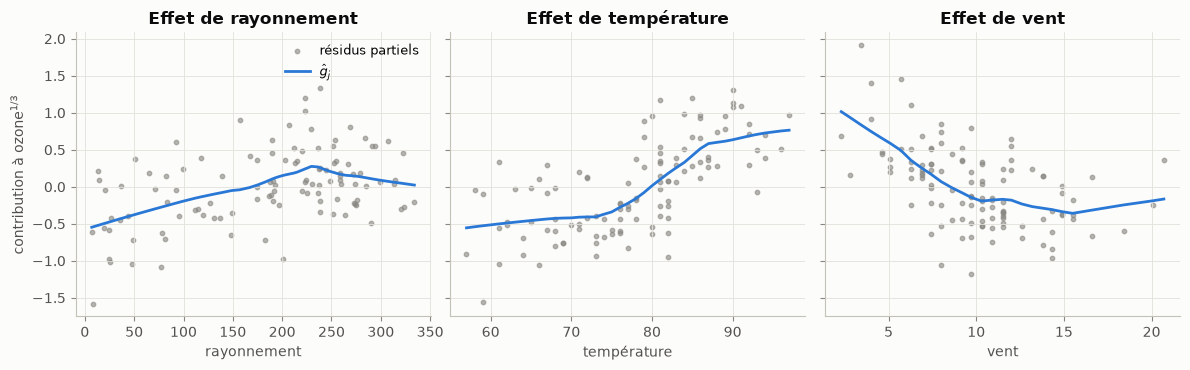

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for j, ax in enumerate(axes):
    o = np.argsort(Xo[:, j])
    ax.scatter(Xo[:, j], gfun[:, j] + res, s=10, color=GRAY, alpha=0.6, label="résidus partiels")
    ax.plot(Xo[o, j], gfun[o, j], color=BLUE, label="$\\hat g_j$")
    ax.set_xlabel(names[j]); ax.set_title("Effet de %s" % names[j])
axes[0].set_ylabel("contribution à ozone$^{1/3}$"); axes[0].legend()
plt.tight_layout(); plt.show()

### Figure 6.9 : graphique conditionnel (« trellis »)

Autre manière de structurer : on regarde l'ozone en fonction du rayonnement,
**conditionnellement** à des intervalles de température et de vent. Dans chaque panneau,
une régression linéaire locale **univariée** est ajustée aux seules données du panneau.
Les intervalles se chevauchent et contiennent chacun environ 40 % des valeurs.

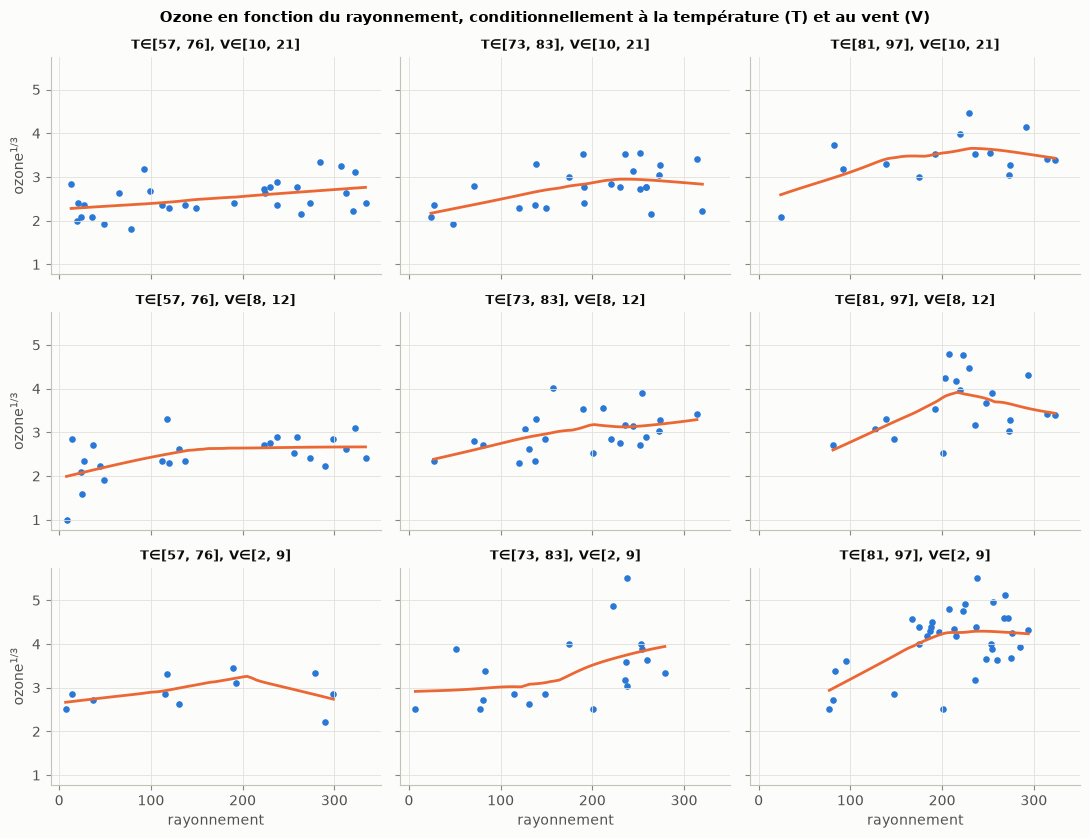

In [9]:
def overlapping_intervals(v, n=3, frac=0.4):
    starts = np.linspace(0, 1 - frac, n)
    return [tuple(np.quantile(v, [s, s + frac])) for s in starts]

t_int = overlapping_intervals(Xo[:, 1])
w_int = overlapping_intervals(Xo[:, 2])
fig, axes = plt.subplots(3, 3, figsize=(11, 8.5), sharex=True, sharey=True)
for a, (wl, wh) in enumerate(w_int[::-1]):
    for b, (tl, th) in enumerate(t_int):
        ax = axes[a, b]
        m = (Xo[:, 1] >= tl) & (Xo[:, 1] <= th) & (Xo[:, 2] >= wl) & (Xo[:, 2] <= wh)
        ax.scatter(Xo[m, 0], yo[m], s=14, color=BLUE)
        if m.sum() >= 5:
            gr = np.linspace(Xo[m, 0].min(), Xo[m, 0].max(), 60)
            ax.plot(gr, nk.local_regression(gr, Xo[m, 0], yo[m], k=max(4, int(0.8 * m.sum())),
                                            degree=1), color=ORANGE)
        ax.set_title("T∈[%d, %d], V∈[%.0f, %.0f]" % (tl, th, wl, wh), fontsize=9)
        if a == 2: ax.set_xlabel("rayonnement")
        if b == 0: ax.set_ylabel("ozone$^{1/3}$")
fig.suptitle("Ozone en fonction du rayonnement, conditionnellement à la température (T) et au vent (V)",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

On lit facilement les interactions : l'effet du rayonnement est fort quand il fait chaud
et que le vent est faible (en bas à droite), presque nul par vent fort et temps frais.

### Modèles à coefficients variables (éq. (6.16)-(6.17))

On sépare les prédicteurs en $(X_1,\dots,X_q)$ et des variables $Z$, et on suppose un
modèle **linéaire en $X$ conditionnellement à $Z$** :
$$
f(X) = \alpha(Z) + \beta_1(Z)X_1 + \cdots + \beta_q(Z)X_q .
$$
On l'ajuste par moindres carrés localement pondérés **en $Z$ seulement** :
$$
\min_{\alpha(z_0),\,\beta(z_0)} \sum_{i=1}^N K_\lambda(z_0, z_i)
\big(y_i - \alpha(z_0) - x_{1i}\beta_1(z_0) - \cdots - x_{qi}\beta_q(z_0)\big)^2 .
$$

Le livre illustre ce modèle sur des mesures du diamètre de l'aorte en fonction de l'âge,
avec des coefficients qui varient selon la profondeur le long de l'aorte (fig. 6.10-6.11).
Ces données n'étant pas publiques, on **simule** un jeu de même nature :
$$
\text{diamètre} = \alpha(z) + \beta(z)\,\text{âge} + \varepsilon,\qquad
\alpha(z) = 12 + 4(1-z)^2,\quad \beta(z) = 0{,}15\,(1-z)^2,
$$
avec $z \in [0,1]$ la profondeur : l'aorte s'épaissit avec l'âge en haut, plus en bas.

In [10]:
n_a = 400
z_a = rng.uniform(0, 1, n_a)
age = rng.uniform(20, 65, n_a)
alpha_true = lambda z: 12 + 4 * (1 - z) ** 2
beta_true = lambda z: 0.15 * (1 - z) ** 2
diam = alpha_true(z_a) + beta_true(z_a) * age + rng.normal(0, 1.5, n_a)
Xa = np.column_stack([age, z_a])

**Mise en œuvre.** On utilise la régression locale générale du module avec
- une métrique $\mathbf A = \operatorname{diag}(0, 1)$ : le noyau ne regarde que $z$ ;
- les monômes $1,\ (x - x_0),\ (z - z_0),\ (x-x_0)(z-z_0)$ : modèle linéaire en âge, dont les
  deux coefficients sont eux-mêmes linéaires locaux en $z$ (c'est l'idée de l'exercice 6.6).

La prédiction en $(x_0, z_0)$ vaut $\hat\alpha(z_0) + \hat\beta(z_0)x_0$, donc
$\hat\alpha(z_0) = \hat f(0, z_0)$ et $\hat\beta(z_0) = \hat f(1, z_0) - \hat f(0, z_0)$.
Tout reste **linéaire en $\mathbf y$**, ce qui donne des erreurs-types.

In [11]:
A = np.diag([0.0, 1.0])
monos = [(0, 0), (1, 0), (0, 1), (1, 1)]
zg = np.linspace(0.02, 0.98, 40)
L0 = nk.local_weights_matrix(np.column_stack([np.zeros_like(zg), zg]), Xa, lam=0.3,
                             kernel="tricube", A=A, monomials=monos)
L1 = nk.local_weights_matrix(np.column_stack([np.ones_like(zg), zg]), Xa, lam=0.3,
                             kernel="tricube", A=A, monomials=monos)
a_hat, b_hat = L0 @ diam, (L1 - L0) @ diam
# variance résiduelle estimée à partir de l'ajustement aux points d'apprentissage
fit_a = nk.local_regression(Xa, Xa, diam, lam=0.3, kernel="tricube", A=A, monomials=monos)
s2 = np.sum((diam - fit_a) ** 2) / (n_a - 8)
se_a, se_b = np.sqrt(s2 * np.sum(L0 ** 2, 1)), np.sqrt(s2 * np.sum((L1 - L0) ** 2, 1))

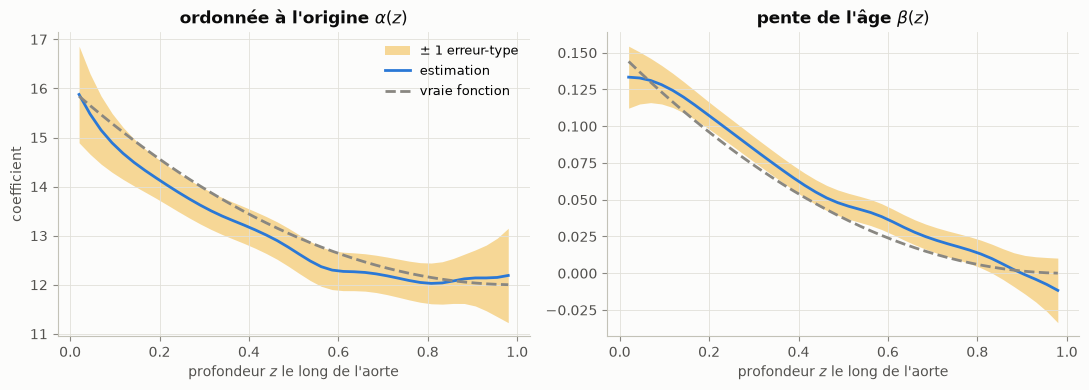

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, est, se, tr, lab in [(axes[0], a_hat, se_a, alpha_true, "ordonnée à l'origine $\\alpha(z)$"),
                             (axes[1], b_hat, se_b, beta_true, "pente de l'âge $\\beta(z)$")]:
    ax.fill_between(zg, est - se, est + se, color=YELLOW, alpha=0.4, lw=0, label="± 1 erreur-type")
    ax.plot(zg, est, color=BLUE, label="estimation")
    ax.plot(zg, tr(zg), color=GRAY, ls="--", label="vraie fonction")
    ax.set_xlabel("profondeur $z$ le long de l'aorte"); ax.set_title(lab)
axes[0].set_ylabel("coefficient"); axes[0].legend()
plt.tight_layout(); plt.show()

Comme dans la figure 6.11 du livre, la pente de l'âge décroît avec la profondeur : la
relation diamètre-âge s'estompe en descendant le long de l'aorte.

## 3. Vraisemblance locale

Tout modèle paramétrique ajusté par une méthode qui accepte des **poids d'observation**
peut être rendu local. Si chaque observation a un paramètre $\theta_i = x_i^T\beta$ et une
log-vraisemblance $l(y_i, x_i^T\beta)$, la **log-vraisemblance locale** en $x_0$ est
$$
l(\beta(x_0)) = \sum_{i=1}^N K_\lambda(x_0, x_i)\; l\big(y_i, x_i^T\beta(x_0)\big),
$$
et l'on pose $\hat\theta(x_0) = x_0^T\hat\beta(x_0)$. Exemples cités par le livre : modèles
linéaires généralisés locaux, coefficients variables par vraisemblance locale, modèles
autorégressifs dont les coefficients varient selon l'historique récent.

### Régression logistique multinomiale locale (éq. (6.18)-(6.20))

Le modèle logistique linéaire à $J$ classes s'écrit
$\Pr(G = j\mid X = x) = e^{\beta_{j0} + \beta_j^Tx}/(1 + \sum_{k=1}^{J-1} e^{\beta_{k0}+\beta_k^Tx})$.
Sa version locale maximise
$$
\sum_{i=1}^N K_\lambda(x_0, x_i)\Big\{\beta_{g_i 0}(x_0) + \beta_{g_i}(x_0)^T(x_i - x_0)
- \log\Big[1 + \sum_{k=1}^{J-1}\exp\big(\beta_{k0}(x_0) + \beta_k(x_0)^T(x_i - x_0)\big)\Big]\Big\}.
$$
Grâce au centrage en $x_0$, la probabilité estimée en $x_0$ ne fait intervenir que les
ordonnées à l'origine : $\hat\Pr(G = j\mid X = x_0) = e^{\hat\beta_{j0}(x_0)}/(1 + \sum_k e^{\hat\beta_{k0}(x_0)})$.

**Algorithme.** Pour deux classes, la log-vraisemblance pondérée est concave ; on la
maximise par Newton-Raphson (IRLS, section 4.4.1 du livre) avec des poids d'observation
égaux aux poids du noyau. Une erreur-type « sandwich » du logit estimé
$\hat\eta(x_0)=\hat\beta_0(x_0)$ s'obtient par
$\widehat{\operatorname{Var}}\,\hat\beta = \mathbf H^{-1}\big(\mathbf B^T\mathbf K^2\mathbf V\mathbf B\big)\mathbf H^{-1}$,
où $\mathbf H = \mathbf B^T\mathbf K\mathbf V\mathbf B$, $\mathbf K$ les poids du noyau,
$\mathbf V = \operatorname{diag}(\hat p_i(1-\hat p_i))$.

### Figure 6.12 : prévalence de la maladie coronarienne (*SAheart*)

On ajuste une régression logistique **linéaire locale** (tri-cube, fenêtre des plus proches
voisins de span 30 %) de `chd` sur la pression systolique, puis sur l'obésité. La bande est
$\operatorname{logit}^{-1}(\hat\eta \pm \widehat{\mathrm{se}})$.

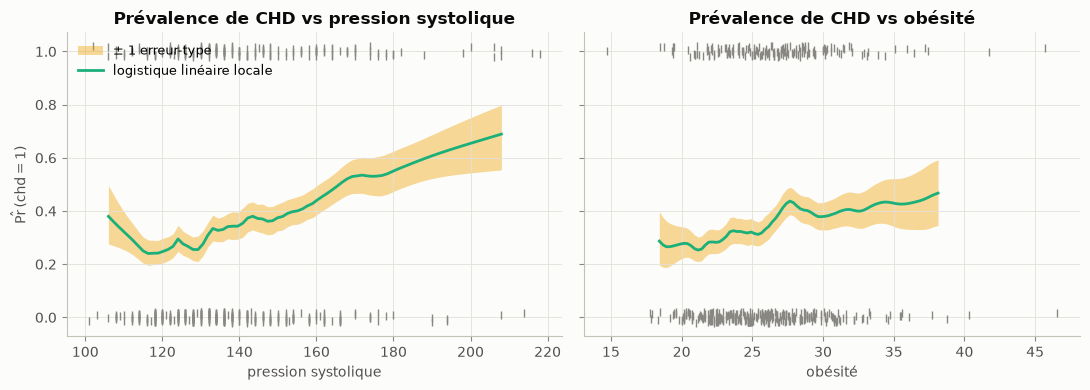

In [13]:
sa = datasets.load_saheart()
chd = sa["chd"].to_numpy()
k_sa = int(0.3 * len(chd))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
expit = lambda t: 1 / (1 + np.exp(-t))
for ax, var, lab in [(axes[0], "sbp", "pression systolique"), (axes[1], "obesity", "obésité")]:
    xv = sa[var].to_numpy(float)
    gr = np.linspace(np.percentile(xv, 1), np.percentile(xv, 99), 80)
    p, se = nk.local_logistic(gr, xv, chd, k=k_sa, degree=1)
    eta = np.log(p / (1 - p))
    ax.fill_between(gr, expit(eta - se), expit(eta + se), color=YELLOW, alpha=0.4, lw=0,
                    label="± 1 erreur-type")
    ax.plot(gr, p, color=GREEN, label="logistique linéaire locale")
    ax.plot(xv, chd + rng.uniform(-0.02, 0.02, len(chd)), "|", color=GRAY, ms=6)
    ax.set_xlabel(lab); ax.set_title("Prévalence de CHD vs %s" % lab)
axes[0].set_ylabel("$\\hat{\\Pr}(\\mathrm{chd} = 1)$"); axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

La remontée inattendue de la prévalence aux **faibles** valeurs s'explique par le
caractère rétrospectif de l'étude : certains malades avaient déjà été traités pour faire
baisser leur tension ou leur poids. Ce lissage local est un outil d'exploration utile pour
détecter des non-linéarités, invisibles sur un nuage de 0 et de 1.

> **Remarque.** On aurait pu lisser directement la variable 0/1 par Nadaraya-Watson : cela
> revient à une logistique localement **constante** (exercice 6.5). Travailler sur l'échelle
> du logit permet de profiter de la correction de biais du linéaire local.

## 4. Estimation de densité par noyau et classification

### L'estimateur de Parzen (éq. (6.21)-(6.22))

Soit $x_1,\dots,x_N$ un échantillon de densité $f_X$. Une estimation naturelle compte les
points dans un petit voisinage de largeur $\lambda$ : $\hat f_X(x_0) = \#\{x_i\in\mathcal N(x_0)\}/(N\lambda)$.
Cet estimateur est cahoteux ; on préfère l'estimateur lisse de **Parzen**
$$
\hat f_X(x_0) = \frac{1}{N\lambda}\sum_{i=1}^N D\!\left(\frac{|x_0 - x_i|}{\lambda}\right),
$$
qui pondère les observations selon leur distance à $x_0$. Si $\int D = 1$ et $D \ge 0$,
$\hat f_X$ est bien une densité : par le changement de variable $u = (x - x_i)/\lambda$,
chaque terme s'intègre en $\frac1{N\lambda}\cdot\lambda = \frac1N$.

### Interprétation : une convolution (éq. (6.23))

Avec le noyau gaussien et $\varphi_\lambda$ la densité de $\mathcal N(0, \lambda^2)$,
$$
\hat f_X(x) = \frac1N\sum_{i=1}^N \varphi_\lambda(x - x_i) = (\hat F \star \varphi_\lambda)(x),
$$
la convolution de la loi empirique $\hat F$ (masse $1/N$ en chaque $x_i$) par
$\varphi_\lambda$ : c'est la densité de $X^* + \lambda Z$ où $X^*\sim\hat F$ et
$Z\sim\mathcal N(0,1)$ indépendants. On « bruite » chaque observation par une gaussienne.

### Figure 6.13 : pression systolique du groupe CHD

Estimation gaussienne avec la largeur de Silverman
$\lambda = 0{,}9\min(\hat\sigma, \mathrm{IQR}/1{,}34)N^{-1/5}$, règle classique qui serait
optimale pour des données gaussiennes, légèrement robustifiée. Les gaussiennes
individuelles $\varphi_\lambda(x - x_i)$ sont divisées par 10 pour la lisibilité.

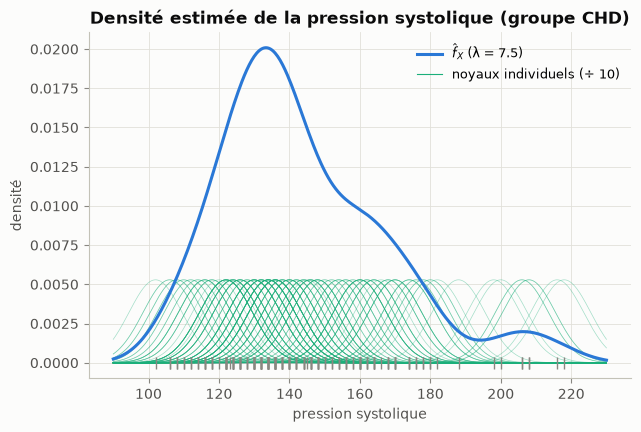

In [14]:
sbp = sa["sbp"].to_numpy(float)
sbp1, sbp0 = sbp[chd == 1], sbp[chd == 0]
lam1 = nk.silverman_bandwidth(sbp1)
gs = np.linspace(90, 230, 400)
plt.figure(figsize=(7, 4.5))
for xi in sbp1:
    plt.plot(gs, nk.gaussian((gs - xi) / lam1) / lam1 / 10, color=GREEN, lw=0.5, alpha=0.4)
plt.plot(gs, nk.kde(gs, sbp1, lam1), color=BLUE, lw=2.2, label="$\\hat f_X$ (λ = %.1f)" % lam1)
plt.plot(sbp1, np.zeros_like(sbp1), "|", color=GRAY, ms=8)
plt.plot([], [], color=GREEN, lw=0.8, label="noyaux individuels (÷ 10)")
plt.title("Densité estimée de la pression systolique (groupe CHD)")
plt.xlabel("pression systolique"); plt.ylabel("densité"); plt.legend(); plt.show()

Le choix de $\lambda$ joue le même rôle qu'en régression : trop petit, la densité est
hérissée de pics (variance) ; trop grand, elle est écrasée (biais).

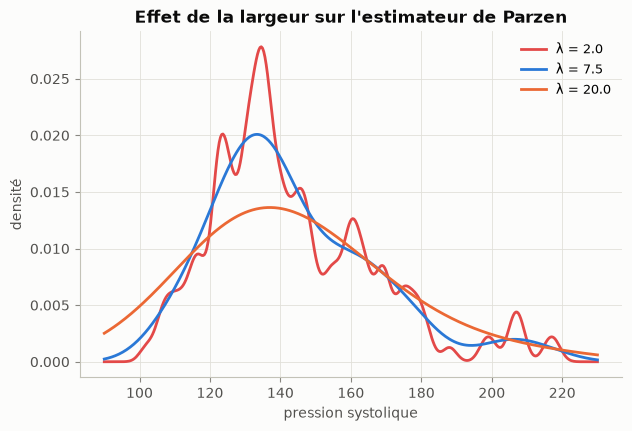

In [15]:
plt.figure(figsize=(7, 4.5))
for lam, c in [(2.0, RED), (lam1, BLUE), (20.0, ORANGE)]:
    plt.plot(gs, nk.kde(gs, sbp1, lam), color=c, label="λ = %.1f" % lam)
plt.title("Effet de la largeur sur l'estimateur de Parzen")
plt.xlabel("pression systolique"); plt.ylabel("densité"); plt.legend(); plt.show()

En dimension $p$, l'analogue gaussien naturel est le noyau produit (éq. (6.24)) :
$\hat f_X(x_0) = \frac{1}{N(2\lambda^2\pi)^{p/2}}\sum_i e^{-\frac12(\|x_i - x_0\|/\lambda)^2}$,
qui souffre bien sûr du fléau de la dimension.

### Classification par densités estimées (éq. (6.25))

Pour $J$ classes, on estime séparément les densités $\hat f_j$ dans chaque classe et les
probabilités a priori $\hat\pi_j$ (proportions observées). La formule de Bayes donne
$$
\hat\Pr(G = j\mid X = x_0) = \frac{\hat\pi_j\hat f_j(x_0)}{\sum_{k=1}^J\hat\pi_k\hat f_k(x_0)} .
$$

### Figure 6.14 : densités par classe et probabilité a posteriori

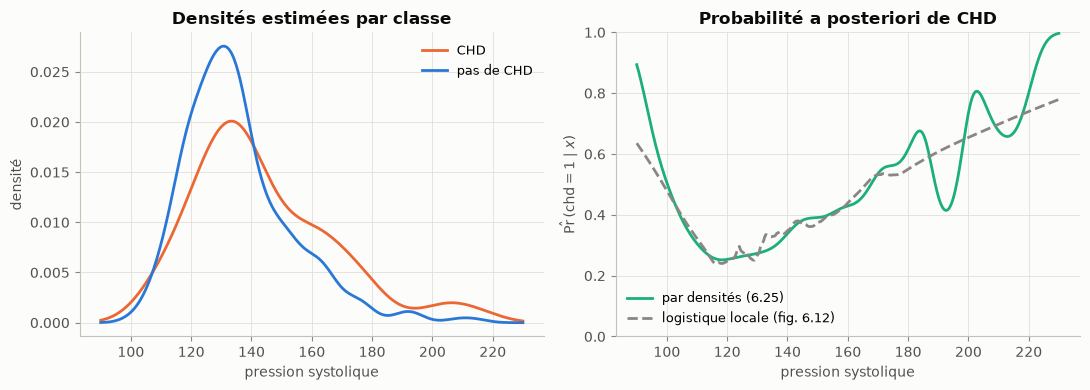

In [16]:
lam0 = nk.silverman_bandwidth(sbp0)
post, _ = nk.kde_posterior(gs, sbp, chd, [lam0, lam1])
p_ll, _ = nk.local_logistic(gs, sbp, chd, k=k_sa, degree=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(gs, nk.kde(gs, sbp1, lam1), color=ORANGE, label="CHD")
axes[0].plot(gs, nk.kde(gs, sbp0, lam0), color=BLUE, label="pas de CHD")
axes[0].set_title("Densités estimées par classe"); axes[0].set_xlabel("pression systolique")
axes[0].set_ylabel("densité"); axes[0].legend()
axes[1].plot(gs, post[:, 1], color=GREEN, label="par densités (6.25)")
axes[1].plot(gs, p_ll, color=GRAY, ls="--", label="logistique locale (fig. 6.12)")
axes[1].set_ylim(0, 1); axes[1].set_title("Probabilité a posteriori de CHD")
axes[1].set_xlabel("pression systolique"); axes[1].set_ylabel("$\\hat{\\Pr}(\\mathrm{chd}=1\\mid x)$")
axes[1].legend()
plt.tight_layout(); plt.show()

La principale différence apparaît aux fortes pressions : les données y sont rares dans
les deux classes, les densités à **fenêtre métrique** y sont petites et très variables,
et leur rapport devient erratique. La logistique locale utilise une fenêtre de **k-ppv**
(qui s'élargit dans cette zone) et l'hypothèse localement linéaire sur l'échelle du logit.

### Figure 6.15 : bien estimer les densités n'est pas nécessaire

Si le but est de classer, seule la probabilité a posteriori compte (et même seulement
près de la frontière $\{x : \Pr(G=1\mid x) = 1/2\}$). Exemple construit : $f_0$ est un
mélange de gaussiennes **multimodal** et $f_1(x) \propto f_0(x)e^{bx}$. Les deux densités
sont très structurées, mais
$\Pr(G = 1\mid x) = \pi_1 f_1/(\pi_0 f_0 + \pi_1 f_1)$ est une simple **logistique** en $x$.

Calcul : si $f_0 = \sum_m w_m\varphi(x;\mu_m,s_m^2)$, on complète le carré dans
l'exponentielle :
$e^{bx}\varphi(x;\mu,s^2) = e^{b\mu + b^2s^2/2}\,\varphi(x;\mu + bs^2, s^2)$. Donc $f_1$ est
encore un mélange gaussien (moyennes décalées de $bs_m^2$, poids
$\propto w_me^{b\mu_m + b^2s_m^2/2}$), et avec $\pi_0 = \pi_1$ :
$\Pr(G = 1\mid x) = 1/(1 + c\,e^{-bx})$ où $c$ est la constante de normalisation.

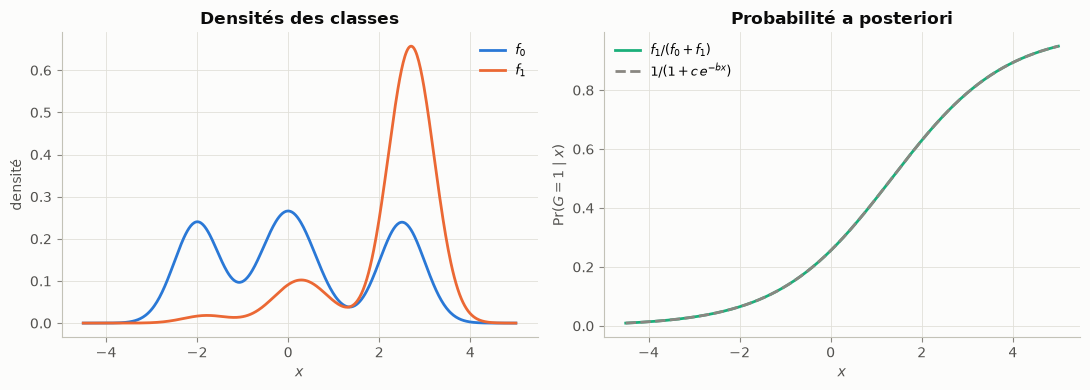

In [17]:
from scipy.stats import norm
w0, mu0, s0 = np.array([0.3, 0.4, 0.3]), np.array([-2.0, 0.0, 2.5]), np.array([0.5, 0.6, 0.5])
b = 0.8
w1 = w0 * np.exp(b * mu0 + b ** 2 * s0 ** 2 / 2)
c = w1.sum()
w1 = w1 / c
mu1 = mu0 + b * s0 ** 2
xs = np.linspace(-4.5, 5, 500)
f0 = sum(w * norm.pdf(xs, m, s) for w, m, s in zip(w0, mu0, s0))
f1 = sum(w * norm.pdf(xs, m, s) for w, m, s in zip(w1, mu1, s0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(xs, f0, color=BLUE, label="$f_0$"); axes[0].plot(xs, f1, color=ORANGE, label="$f_1$")
axes[0].set_title("Densités des classes"); axes[0].set_xlabel("$x$"); axes[0].set_ylabel("densité")
axes[0].legend()
axes[1].plot(xs, f1 / (f0 + f1), color=GREEN, label="$f_1/(f_0+f_1)$")
axes[1].plot(xs, 1 / (1 + c * np.exp(-b * xs)), color=GRAY, ls="--", label="$1/(1+c\\,e^{-bx})$")
axes[1].set_title("Probabilité a posteriori"); axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$\\Pr(G=1\\mid x)$"); axes[1].legend()
plt.tight_layout(); plt.show()

### Le classifieur bayésien naïf (éq. (6.26)-(6.27))

En grande dimension, estimer $f_j$ est hors de portée. Le **Bayes naïf** suppose que,
dans chaque classe, les variables sont **indépendantes** :
$$
f_j(X) = \prod_{k=1}^p f_{jk}(X_k).
$$
Chaque marge $f_{jk}$ s'estime par un noyau unidimensionnel (ou par un histogramme si
$X_k$ est discrète, ce qui permet de mélanger les types de variables).

Le logit a posteriori se décompose alors (on prend la classe $J$ comme référence) :
$$
\log\frac{\Pr(G=\ell\mid X)}{\Pr(G=J\mid X)} = \log\frac{\pi_\ell f_\ell(X)}{\pi_J f_J(X)}
= \log\frac{\pi_\ell}{\pi_J} + \sum_{k=1}^p \log\frac{f_{\ell k}(X_k)}{f_{Jk}(X_k)}
= \alpha_\ell + \sum_{k=1}^p g_{\ell k}(X_k) :
$$
c'est la forme d'un **modèle additif généralisé** (chapitre 9), mais estimé tout autrement
(exercice 6.9). L'hypothèse est presque toujours fausse, et pourtant le Bayes naïf
fonctionne souvent bien : le biais sur les densités nuit peu aux probabilités a posteriori
près de la frontière, et l'on gagne beaucoup en variance.

Application aux données *SAheart* (9 prédicteurs, `famhist` discrète), comparée à la
régression logistique linéaire, par validation croisée à 10 plis.

In [18]:
cols = ["sbp", "tobacco", "ldl", "adiposity", "famhist", "typea", "obesity", "alcohol", "age"]
Xs = sa[cols].to_numpy(float)
folds = rng.permutation(len(chd)) % 10
err_nb, err_lr = [], []
for f in range(10):
    tr, te = folds != f, folds == f
    nb = nk.NaiveBayesKDE(discrete=[c == "famhist" for c in cols], bw_factor=2.0).fit(Xs[tr], chd[tr])
    err_nb.append(np.mean(nb.predict(Xs[te]) != chd[te]))
    m, s = Xs[tr].mean(0), Xs[tr].std(0)
    Z = np.column_stack([np.ones(tr.sum()), (Xs[tr] - m) / s])
    beta = nk.logistic_irls(Z, chd[tr])
    Zt = np.column_stack([np.ones(te.sum()), (Xs[te] - m) / s])
    err_lr.append(np.mean((Zt @ beta > 0) != chd[te]))
print("erreur CV  Bayes naïf (noyaux) : %.3f ± %.3f" % (np.mean(err_nb), np.std(err_nb) / np.sqrt(10)))
print("erreur CV  logistique linéaire : %.3f ± %.3f" % (np.mean(err_lr), np.std(err_lr) / np.sqrt(10)))

erreur CV  Bayes naïf (noyaux) : 0.301 ± 0.018
erreur CV  logistique linéaire : 0.273 ± 0.021


Le Bayes naïf fait un peu moins bien que la logistique ici (quelques variables, assez
corrélées : `adiposity` et `obesity` par exemple), mais reste raisonnable. On peut
visualiser ses fonctions additives $g_k(x_k) = \log\hat f_{1k}(x_k)/\hat f_{0k}(x_k)$ :

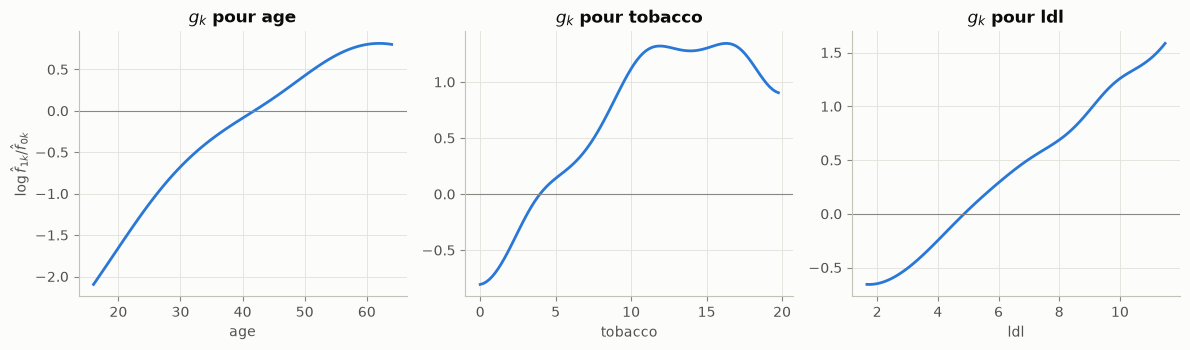

In [19]:
nb = nk.NaiveBayesKDE(discrete=[c == "famhist" for c in cols], bw_factor=2.0).fit(Xs, chd)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, var in zip(axes, ["age", "tobacco", "ldl"]):
    j = cols.index(var)
    gr = np.linspace(*np.percentile(Xs[:, j], [1, 99]), 100)
    Xg_ = np.tile(np.median(Xs, 0), (100, 1)); Xg_[:, j] = gr
    lm = nb.log_marginals(Xg_)
    ax.plot(gr, lm[:, 1, j] - lm[:, 0, j], color=BLUE)
    ax.axhline(0, color=GRAY, lw=0.8)
    ax.set_xlabel(var); ax.set_title("$g_k$ pour %s" % var)
axes[0].set_ylabel("$\\log \\hat f_{1k}/\\hat f_{0k}$")
plt.tight_layout(); plt.show()

## 5. Fonctions de base radiales (éq. (6.28)-(6.31))

Les **fonctions de base radiales** utilisent les noyaux comme fonctions de base :
$$
f(x) = \sum_{j=1}^M K_{\lambda_j}(\xi_j, x)\,\beta_j = \sum_{j=1}^M D\!\left(\frac{\|x-\xi_j\|}{\lambda_j}\right)\beta_j,
$$
chaque fonction étant indexée par un **centre** (prototype) $\xi_j$ et une **échelle**
$\lambda_j$. Pour apprendre les paramètres :
- on peut tout optimiser par moindres carrés (éq. (6.29), « réseau RBF ») : problème non
  convexe, à minima locaux, proche des réseaux de neurones ;
- ou fixer d'abord $(\xi_j, \lambda_j)$ de façon non supervisée (mélange gaussien,
  classification), puis obtenir les $\beta_j$ par simple régression linéaire.

### Figure 6.16 : les « trous » et la renormalisation

Avec une largeur commune $\lambda$, des régions peuvent n'être couvertes par aucune
fonction de base. Les fonctions **renormalisées** (éq. (6.30))
$$
h_j(x) = \frac{D(\|x - \xi_j\|/\lambda)}{\sum_{k=1}^M D(\|x - \xi_k\|/\lambda)}
$$
forment une partition de l'unité ($\sum_j h_j = 1$) et évitent ce problème ; elles
ressemblent un peu aux B-splines.

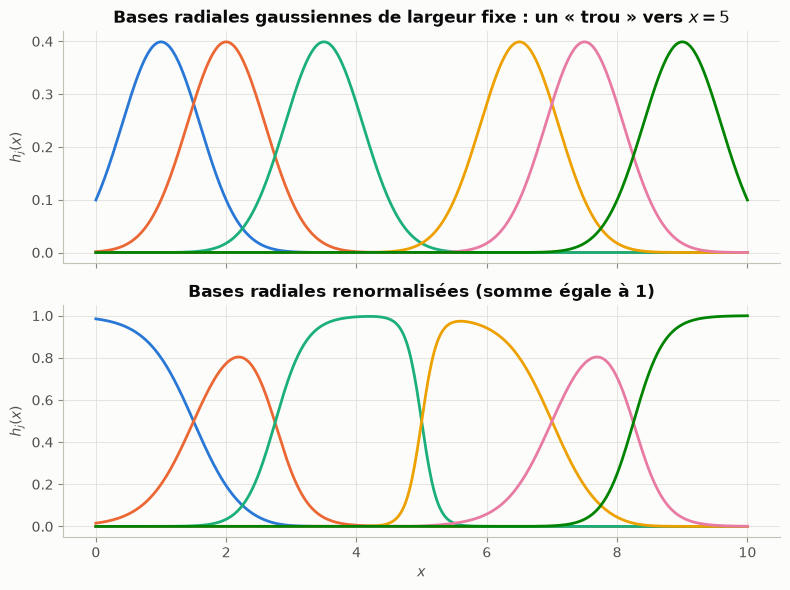

In [20]:
centers = np.array([1.0, 2.0, 3.5, 6.5, 7.5, 9.0])
xr = np.linspace(0, 10, 500)
H = nk.rbf_basis(xr, centers, 0.6)
Hn = nk.rbf_basis(xr, centers, 0.6, normalized=True)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for j in range(len(centers)):
    axes[0].plot(xr, H[:, j], color=COLORS[j])
    axes[1].plot(xr, Hn[:, j], color=COLORS[j])
axes[0].set_title("Bases radiales gaussiennes de largeur fixe : un « trou » vers $x = 5$")
axes[1].set_title("Bases radiales renormalisées (somme égale à 1)")
axes[1].set_xlabel("$x$")
for ax in axes: ax.set_ylabel("$h_j(x)$")
plt.tight_layout(); plt.show()

Ajustons par moindres carrés une fonction sur ces deux bases : dans le trou, la base non
renormalisée force l'ajustement vers 0, la base renormalisée interpole en douceur.